In [ ]:
pip install requests

In [ ]:
import requests
import pandas as pd
from collections import Counter
import matplotlib.pyplot as plt

rows = []
limit = 100

for page_number in range(6):
    params = {
        "text": "аналитик данных",
        "limit": limit,
        "offset": page_number
    }

    response = requests.get(url, params=params, timeout=30)
    response.raise_for_status()

    page = response.json().get("results", {}).get("vacancies", [])
    rows.extend(page)

    print("Страница:", page_number + 1, "| Вакансий:", len(page))

df = pd.json_normalize(rows).drop_duplicates(subset="id")

data_analyst_df = df[
    df["job-name"].str.contains(
        r"аналитик данных|аналитик больших данных",
        case=False,
        na=False
    )
].copy()

data_analyst_df["salary_min_clean"] = pd.to_numeric(
    data_analyst_df["salary_min"], errors="coerce"
)
data_analyst_df.loc[
    data_analyst_df["salary_min_clean"] <= 0,
    "salary_min_clean"
] = float("nan")

print("Вакансий аналитиков данных:", len(data_analyst_df))

NameError: name 'url' is not defined

Смотрим, какие поля есть в таблице и где не хватает данных

In [ ]:
print("Вакансий:", len(df))
print("Столбцы:", df.columns.tolist())

print("\nГде больше всего пропусков:")
display(df.isna().sum().sort_values(ascending=False).head(15))

Вакансий: 506
Столбцы: ['id', 'source', 'creation-date', 'date_modify', 'salary', 'salary_min', 'salary_max', 'job-name', 'vac_url', 'employment', 'schedule', 'qualification', 'requirements', 'duty', 'social_protected', 'contact_list', 'contact_person', 'work_places', 'code_profession', 'typicalPosition', 'skills', 'shift', 'benefit', 'trainingDays', 'currency', 'region.region_code', 'region.name', 'company.companycode', 'company.email', 'company.hr-agency', 'company.inn', 'company.kpp', 'company.name', 'company.ogrn', 'company.site', 'company.url', 'category.specialisation', 'requirement.education', 'requirement.experience', 'addresses.address', 'workPlaceType.workPlaceDisabilityGroup', 'workPlaceType.workPlaceForeign', 'workPlaceType.workPlaceOrdinary', 'workPlaceType.workPlaceQuota', 'workPlaceType.workPlaceSocialProtected', 'workPlaceType.workPlaceSpecial', 'medicalDocuments', 'medicalCertificate', 'conditions', 'hireDate', 'addressOffice', 'benefitDetails', 'workPlaceType.workPlac

,0
category.industry,505
scheduleTypeComment,501
benefitDetails,499
medicalCertificate,495
workPlaceType.workPlaceSocialProtectedOthers,493
addressOffice,482
requirement.qualification,477
term.text,476
hireDate,452
benefit,428


Разведочный анализ данных: дублирование, пропуски

In [ ]:
columns = [
    "job-name", "salary_min", "salary_max", "currency",
    "region.name", "skills", "requirement.experience", "creation-date"
]

quality = pd.DataFrame({
    "пустых значений": df[columns].isna().sum(),
    "пустых, %": (df[columns].isna().mean() * 100).round(1),
    "разных значений": [
        df[column].dropna().astype(str).nunique()
        for column in columns
    ]
}, index=columns)

display(quality)

print("Повторяющихся ID:", df["id"].duplicated().sum())

print("Примеры зарплат:")
display(df[["salary", "salary_min", "salary_max", "currency"]].head(10))

,пустых значений,"пустых, %",разных значений
job-name,0,0.0,291
salary_min,0,0.0,128
salary_max,0,0.0,106
currency,0,0.0,1
region.name,0,0.0,66
skills,0,0.0,82
requirement.experience,0,0.0,8
creation-date,0,0.0,207


Повторяющихся ID: 0
Примеры зарплат:


,salary,salary_min,salary_max,currency
0,от 75000,75000,200000,«руб.»
1,от 80000,80000,80000,«руб.»
2,от 220000,220000,220000,«руб.»
3,от 0,0,0,«руб.»
4,от 0,0,0,«руб.»
5,от 92000,92000,0,«руб.»
6,от 100000,100000,140000,«руб.»
7,от 150000,150000,150000,«руб.»
8,от 75000,75000,78000,«руб.»
9,от 88000,88000,0,«руб.»


In [ ]:
for column in ["salary", "salary_min", "salary_max", "currency", "requirement.experience"]:
    print("\n", column)
    print(df[column].astype(str).value_counts().head(10))


 salary
salary
от 100000    44
от 50000     42
от 0         30
от 40000     27
от 30000     26
от 80000     23
от 60000     22
от 70000     20
от 150000    17
от 27093     15
Name: count, dtype: int64

 salary_min
salary_min
100000    44
50000     42
0         30
40000     27
30000     26
80000     23
60000     22
70000     20
150000    17
27093     15
Name: count, dtype: int64

 salary_max
salary_max
0         99
100000    38
80000     32
90000     26
60000     24
50000     20
150000    19
70000     16
120000    15
200000    13
Name: count, dtype: int64

 currency
currency
«руб.»    506
Name: count, dtype: int64

 requirement.experience
requirement.experience
3    143
1    117
0     86
5     62
7     38
6     30
4     25
2      5
Name: count, dtype: int64


In [ ]:
zero_salary = df[
    (df["salary_min"] == 0) | (df["salary_max"] == 0)
]

display(zero_salary[
    ["job-name", "salary", "salary_min", "salary_max", "region.name", "vac_url"]
])

,job-name,salary,salary_min,salary_max,region.name,vac_url
3,Аналитик данных,от 0,0,0,Город Москва,https://trudvsem.ru/vacancy/card/5147746474134...
4,Аналитик данных,от 0,0,0,Город Москва,https://trudvsem.ru/vacancy/card/5147746474134...
5,Аналитик данных,от 92000,92000,0,Воронежская область,https://trudvsem.ru/vacancy/card/5147746474134...
9,Аналитик данных,от 88000,88000,0,Нижегородская область,https://trudvsem.ru/vacancy/card/5147746474134...
10,Аналитик данных финансы,от 0,0,0,Город Москва,https://trudvsem.ru/vacancy/card/5147746474134...
...,...,...,...,...,...,...
494,Аналитик,от 27093,27093,0,Город Москва,https://trudvsem.ru/vacancy/card/7226c750-02f1...
498,Java-разработчик (Senior),от 343300,343300,0,Город Москва,https://trudvsem.ru/vacancy/card/5147746474134...
499,Директор по управлению продуктом (профильный р...,от 0,0,0,Город Москва,https://trudvsem.ru/vacancy/card/1027700404797...
500,Академический директор экосистемы «ЕГЭ ПЛЮС»,от 100000,100000,0,Город Москва,https://trudvsem.ru/vacancy/card/7226c750-02f1...


In [ ]:
clean_df = df.copy()

clean_df["salary_min_clean"] = clean_df["salary_min"].where(
    clean_df["salary_min"] > 0
)
clean_df["salary_max_clean"] = clean_df["salary_max"].where(
    clean_df["salary_max"] > 0
)

clean_df["salary_status"] = "указана сумма"
clean_df.loc[
    (df["salary_min"] == 0) & (df["salary_max"] == 0),
    "salary_status"
] = "зарплата не указана"
clean_df.loc[
    (df["salary_min"] > 0) & (df["salary_max"] == 0),
    "salary_status"
] = "указана только зарплата «от»"

print(clean_df["salary_status"].value_counts())

display(clean_df[
    ["job-name", "salary", "salary_min_clean", "salary_max_clean", "salary_status"]
].head(10))

salary_status
указана сумма                   407
указана только зарплата «от»     69
зарплата не указана              30
Name: count, dtype: int64


,job-name,salary,salary_min_clean,salary_max_clean,salary_status
0,Аналитик данных,от 75000,75000.0,200000.0,указана сумма
1,Аналитик данных,от 80000,80000.0,80000.0,указана сумма
2,Главный аналитик данных,от 220000,220000.0,220000.0,указана сумма
3,Аналитик данных,от 0,NaN,NaN,зарплата не указана
4,Аналитик данных,от 0,NaN,NaN,зарплата не указана
5,Аналитик данных,от 92000,92000.0,NaN,указана только зарплата «от»
6,Ведущий аналитик данных,от 100000,100000.0,140000.0,указана сумма
7,Аналитик данных,от 150000,150000.0,150000.0,указана сумма
8,Аналитик данных,от 75000,75000.0,78000.0,указана сумма
9,Аналитик данных,от 88000,88000.0,NaN,указана только зарплата «от»


In [ ]:
region_summary = (
    clean_df.groupby("region.name")
    .agg(
        vacancy_count=("id", "count"),
        vacancies_with_salary=("salary_min_clean", "count"),
        median_salary_floor=("salary_min_clean", "median")
    )
    .reset_index()
)

region_summary = region_summary[
    (region_summary["vacancy_count"] >= 3)
    & (region_summary["vacancies_with_salary"] > 0)
]

region_summary = region_summary.sort_values(
    "median_salary_floor",
    ascending=False
)

display(region_summary)

,region.name,vacancy_count,vacancies_with_salary,median_salary_floor
30,Мурманская область,3,3,238179.0
10,Город Москва,140,120,120000.0
16,Иркутская область,3,3,100000.0
39,Республика Башкортостан,3,3,100000.0
47,Ростовская область,9,8,90000.0
31,Нижегородская область,11,10,88000.0
11,Город Санкт-Петербург,43,42,87000.0
9,Воронежская область,8,8,80000.0
63,Ханты-Мансийский автономный округ - Югра,3,3,79000.0
18,Калининградская область,6,6,75000.0


In [ ]:
print("Skills value type:", type(clean_df["skills"].iloc[0]))
display(clean_df[["job-name", "skills"]].head(10))

Skills value type: <class 'list'>


,job-name,skills
0,Аналитик данных,[]
1,Аналитик данных,[]
2,Главный аналитик данных,[]
3,Аналитик данных,[]
4,Аналитик данных,[]
5,Аналитик данных,[]
6,Ведущий аналитик данных,"[Microsoft Power BI, Pandas, MySQL, Microsoft ..."
7,Аналитик данных,[]
8,Аналитик данных,[]
9,Аналитик данных,[]


In [ ]:
from collections import Counter

skill_counts = Counter()
vacancies_with_skills = 0

for skills in clean_df["skills"]:
    if not isinstance(skills, list):
        continue

    unique_skills = {
        skill.strip()
        for skill in skills
        if isinstance(skill, str) and skill.strip()
    }

    if unique_skills:
        vacancies_with_skills += 1

    skill_counts.update(unique_skills)

print("Vacancies with skills listed:", vacancies_with_skills, "of", len(clean_df))
print("Most common skills:", skill_counts.most_common(15))

Vacancies with skills listed: 83 of 506
Most common skills: [('Сопровождение программного обеспечения', 14), ('Навык работы с 1С (программами семейства 1С)', 12), ('Консультирование пользователей', 12), ('Написание тестов и тестирование программного кода', 9), ('Навык работы с SQL', 7), ('Разработка программного обеспечения', 7), ('Навык работы с Python / Питон', 6), ('Написание запросов', 6), ('Навыки программирования', 6), ('Консультирование/поддержка пользователей', 6), ('Экономический анализ', 6), ('Pandas', 5), ('Стрессоустойчивость', 5), ('Умение разбираться и работать с чужим кодом', 5), ('Разработка нового функционала', 5)]


In [ ]:
display(clean_df["job-name"].value_counts().head(20))

,count
job-name,
Фармацевт,61
Программист,26
Аналитик данных,16
Аналитик,13
Инженер-программист,13
Экономист,12
Системный аналитик,10
Учетчик на склад,6
Фармацевт-провизор,6


In [ ]:
data_analyst_df = clean_df[
    clean_df["job-name"].str.contains(
        r"аналитик данных|аналитик больших данных",
        case=False,
        na=False
    )
].copy()

print("Data analyst vacancies:", len(data_analyst_df))
print(data_analyst_df["job-name"].value_counts())

Data analyst vacancies: 25
job-name
Аналитик данных                                       16
Ведущий аналитик данных                                2
Главный аналитик данных                                1
Аналитик данных финансы                                1
Аналитик данных (Корпоративный кредитный портфель)     1
Аналитик данных согласно ОКПДТР-2025                   1
аналитик данных ИИ                                     1
Аналитик больших данных                                1
Ведущий аналитик больших данных                        1
Name: count, dtype: int64


In [ ]:
salary_floors = data_analyst_df["salary_min_clean"].dropna()

print("Вакансий в выборке:", len(data_analyst_df))
print("С указанной нижней границей зарплаты:", len(salary_floors))
print("Без указанной нижней границы:", len(data_analyst_df) - len(salary_floors))
print("Медианная нижняя граница зарплаты:", salary_floors.median())
print("Минимальная нижняя граница:", salary_floors.min())
print("Максимальная нижняя граница:", salary_floors.max())

Вакансий в выборке: 25
С указанной нижней границей зарплаты: 21
Без указанной нижней границы: 4
Медианная нижняя граница зарплаты: 92000.0
Минимальная нижняя граница: 40000.0
Максимальная нижняя граница: 220000.0


In [ ]:
from collections import Counter

data_analyst_skill_counts = Counter()
data_analyst_with_skills = 0

for skills in data_analyst_df["skills"]:
    if not isinstance(skills, list):
        continue

    unique_skills = {
        skill.strip()
        for skill in skills
        if isinstance(skill, str) and skill.strip()
    }

    if unique_skills:
        data_analyst_with_skills += 1

    data_analyst_skill_counts.update(unique_skills)

print(
    "Вакансий с указанными навыками:",
    data_analyst_with_skills,
    "из",
    len(data_analyst_df)
)
print("Частые навыки:", data_analyst_skill_counts.most_common(15))

Вакансий с указанными навыками: 8 из 25
Частые навыки: [('Навык работы с Python / Питон', 6), ('Pandas', 5), ('Навык работы с SQL', 4), ('Большая языковая модель / Large language model (LLM)', 3), ('FastAPI', 2), ('Машинное обучение / Machine Learning (ML)', 2), ('MySQL', 1), ('Microsoft Power BI', 1), ('Обработка естественного языка / Natural language processing (NLP)', 1), ('Kubernetes (k8s)', 1), ('Знание Kubernetes (k8s)', 1), ('Ответственность\xa0, добросовестность', 1), ('Знания в области Data Quality', 1), ('Навык работы с 1С (программами семейства 1С)', 1), ('Навык работы с DWH (Data Warehouse) / Хранилищем данных', 1)]


In [ ]:
print(
    data_analyst_df["requirement.experience"]
    .value_counts(dropna=False)
    .sort_index()
)

requirement.experience
0    2
1    8
3    6
4    2
5    6
6    1
Name: count, dtype: int64


<Axes: title={'center': 'Нижняя граница зарплаты, руб.'}>

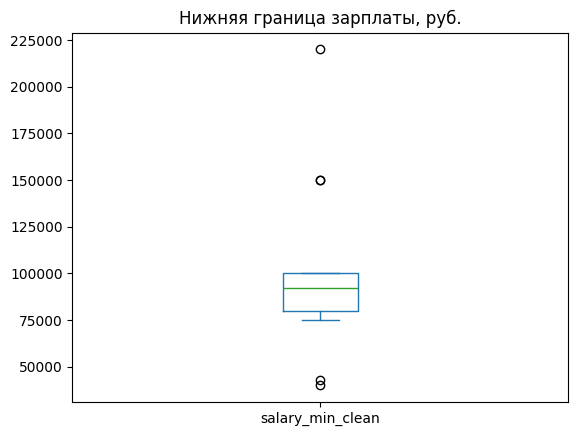

In [ ]:
data_analyst_df["salary_min_clean"].dropna().plot.box(
    title="Нижняя граница зарплаты, руб."
)